In [1]:
import pandas as pd

In [2]:
ecoh = pd.read_csv("ecoh_out.tsv", sep="\t")



In [3]:
unique_seqs = set(ecoh.SEQUENCE)
seqs_otypes = {}

In [4]:
seqs_otypes = {}
for entry in ecoh.iterrows():
    entry_seq = entry[1].get("SEQUENCE")

    entry_gene = entry[1].get("GENE")
    entry_otype = entry_gene.split("-", 1)[1]
    if seqs_otypes.get(entry_seq) is None:
        seqs_otypes[entry_seq] = [entry_otype]
    else:

        seqs_otypes[entry_seq] = seqs_otypes[entry_seq] + [entry_otype]

In [5]:
seqs_otypes

seqs_otypes_final = {}
for seq in seqs_otypes.keys():
    if len(seqs_otypes[seq]) == 2:
        if seqs_otypes[seq][0] != seqs_otypes[seq][1]:
            print("mismatch", seq, seqs_otypes[seq])

        else:
            seqs_otypes_final[seq] = seqs_otypes[seq][0]

seqs_otypes_final = pd.Series(seqs_otypes_final)
seqs_otypes_final_df = seqs_otypes_final.to_frame(name="serotype")
seqs_otypes_final_df.index.name = "locus"

counts = seqs_otypes_final.value_counts()
maintain = counts[counts >= 5]
# Exclude O8, O9 and O62 antigens from analysis
maintain.drop("O8", inplace=True)
#maintain.drop("O9", inplace=True)
maintain.drop("O62-Gp14", inplace=True)
print(maintain.index)
seqs_otypes_final_df_pruned = seqs_otypes_final_df[seqs_otypes_final_df["serotype"].isin(maintain.index)]


mismatch NC_017626.1 ['O17-O44-O77-Gp9', 'O44-Gp9']
mismatch NZ_ABACVG020000001.1 ['O8', 'O153var2']
mismatch NZ_AP021896.1 ['Onovel3', 'O10']
mismatch NZ_AP022003.1 ['O2-O50-Gp7', 'O2-Gp7']
mismatch NZ_AP022159.1 ['O2-O50-Gp7', 'O2-Gp7']
mismatch NZ_AP022221.1 ['O2-O50-Gp7', 'O2-Gp7']
mismatch NZ_AP022261.1 ['O17-O44-O77-Gp9', 'O17-O77-Gp9']
mismatch NZ_AP022287.1 ['O2-O50-Gp7', 'O2-Gp7']
mismatch NZ_AP027487.1 ['Onovel3', 'O10']
mismatch NZ_AP027637.1 ['O2-O50-Gp7', 'O2-Gp7']
mismatch NZ_AP027873.1 ['Onovel3', 'O10']
mismatch NZ_AP027877.1 ['O73-Gp9', 'O17-O77-Gp9']
mismatch NZ_AP029046.1 ['O17-O44-O77-Gp9', 'O17-O77-Gp9']
mismatch NZ_AP042551.1 ['O118-Gp3', 'O151-Gp3']
mismatch NZ_AP042644.1 ['O118-Gp3', 'O151-Gp3']
mismatch NZ_AP043625.1 ['O2-O50-Gp7', 'O2-Gp7']
mismatch NZ_AP043630.1 ['O17-O44-O77-Gp9', 'O17-O77-Gp9']
mismatch NZ_AP043637.1 ['O17-O44-O77-Gp9', 'O17-O77-Gp9']
mismatch NZ_AP045049.1 ['O17-O44-O77-Gp9', 'O17-O77-Gp9']
mismatch NZ_AP045053.1 ['O17-O44-O77-Gp9', 'O17-O

In [6]:
seqs_otypes_final

NC_000913.3           O16
NC_002695.2          O157
NC_004431.1            O6
NC_007779.1           O16
NC_007946.1      O18-Gp12
                   ...   
NZ_OZ369451.1         O25
NZ_OZ369455.1         O25
NZ_OZ369460.1         O25
NZ_OZ369465.1         O25
NZ_OZ369470.1         O25
Length: 3704, dtype: str

In [7]:
import pandas as pd
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.model_selection import StratifiedKFold
import matplotlib.pyplot as plt

In [8]:
pa = pd.read_csv("matrix.csv")
pa = pa.transpose()
pa = pa.iloc[14:]
pa.fillna(0, inplace=True)
pa.replace(regex={r'\D+': 1}, inplace=True)
pa = pa.astype(float)


/var/folders/z8/0w6j6rj97tsc58vfqms6447h0000gp/T/ipykernel_47808/1285612029.py:1: DtypeWarning: Columns (0: NZ_CP182383.1, 1: NZ_CP058355.1, 2: NZ_CP116976.1, 3: NZ_CP079772.1, 4: NZ_CP086627.1, 5: NZ_CP188163.1, 6: NZ_CP076706.1, 7: NZ_CP194953.1, 8: NZ_CP195014.1, 9: NZ_CP135658.1, 10: NZ_CP023849.1, 11: NZ_AP023190.1, 12: NZ_CP074726.1, 13: NZ_AP039429.1, 14: NZ_OZ369436.1, 15: NZ_AP044767.1, 16: NZ_CM166346.1, 17: NZ_CP116900.1, 18: NZ_CP146019.1, 19: NZ_CP076243.1, 20: NZ_CP145513.1, 21: NZ_CP028677.1, 22: NZ_CP196743.1, 23: NZ_CM149693.1, 24: NZ_CP069571.1, 25: NZ_CP182512.1, 26: NZ_CP132983.1, 27: NZ_CP034806.1, 28: NZ_CP115343.1, 29: NZ_CM146020.1, 30: NZ_CP090611.1, 31: NZ_CP149449.1, 32: NZ_CP027587.1, 33: NZ_CM136155.1, 34: NZ_CP184143.1, 35: NZ_LR134311.1, 36: NZ_CP195958.1, 37: NZ_AP042652.1, 38: NZ_CP098880.1, 39: NZ_CP129263.1, 40: NZ_CP070103.1, 41: NZ_CM132948.1, 42: NZ_CM148343.1, 43: NZ_CP128590.1, 44: NZ_CP100876.1, 45: NZ_CP032066.1, 46: NZ_CP051700.1, 47: NZ_CP010

In [9]:

# Subset the matrix to only labelled loci
train_matrix = pa.loc[pa.index.intersection(seqs_otypes_final_df_pruned.index)]
train_matrix.fillna(0, inplace=True)
train_matrix.replace(regex={r'\D+': 1}, inplace=True)
train_matrix = train_matrix.astype(float)
train_labels = seqs_otypes_final_df_pruned.loc[train_matrix.index, "serotype"]

In [10]:
# Compute pairwise Jaccard distances among labelled loci
jaccard_dist = pdist(train_matrix.values, metric="jaccard")

# Build the linkage tree (UPGMA / average linkage is default and well-behaved)
# Ward linkage is also valid but assumes spherical clusters; average is safer for pangenome data
linkage_matrix = linkage(jaccard_dist, method="average")

In [19]:
def evaluate_threshold(z, labels, threshold):
    """Return ARI and NMI for a given linkage cut threshold."""
    clusters = fcluster(z, t=threshold, criterion="distance")
    ari = adjusted_rand_score(labels, clusters)
    nmi = normalized_mutual_info_score(labels, clusters)
    return ari, nmi, len(set(clusters))

# Explore thresholds from near-zero up to the maximum observed distance
thresholds = np.linspace(0.01, np.max(linkage_matrix[:, 2]), 200)

results = []
for t in thresholds:
    ari, nmi, n_clusters = evaluate_threshold(linkage_matrix, train_labels.values, t)
    results.append({
        "threshold": t,
        "ari": ari,
        "nmi": nmi,
        "n_clusters": n_clusters
    })

results_df = pd.DataFrame(results)

# Identify the threshold that maximises ARI
best_idx = results_df["nmi"].idxmax()
best_threshold = results_df.loc[best_idx, "threshold"]
best_ari = results_df.loc[best_idx, "nmi"]
best_n_clusters = int(results_df.loc[best_idx, "n_clusters"])

print(f"Optimal threshold (max ARI): {best_threshold:.4f}")
print(f"  ARI = {best_ari:.4f}")
print(f"  Number of clusters: {best_n_clusters}")
print(len(set(train_labels.values)))

Optimal threshold (max ARI): 0.5025
  ARI = 0.9976
  Number of clusters: 126
122


['DejaVu Sans', 'cmsy10', 'DejaVu Sans Mono', 'STIXSizeTwoSym', 'STIXNonUnicode', 'cmtt10', 'STIXSizeFiveSym', 'STIXSizeFourSym', 'DejaVu Sans Display', 'STIXSizeFourSym', 'DejaVu Serif', 'DejaVu Sans Mono', 'DejaVu Sans Mono', 'STIXNonUnicode', 'STIXGeneral', 'cmr10', 'DejaVu Serif', 'DejaVu Sans', 'cmb10', 'DejaVu Sans', 'STIXGeneral', 'STIXNonUnicode', 'STIXNonUnicode', 'cmex10', 'DejaVu Serif Display', 'STIXSizeTwoSym', 'STIXSizeOneSym', 'cmss10', 'STIXSizeThreeSym', 'STIXGeneral', 'DejaVu Serif', 'DejaVu Sans', 'STIXSizeOneSym', 'STIXGeneral', 'DejaVu Serif', 'STIXSizeThreeSym', 'DejaVu Sans Mono', 'cmmi10', 'Tahoma', 'Baghdad', 'Impact', 'Trebuchet MS', 'UQ Erode', 'PT Sans', 'Sukhumvit Set', 'JetBrainsMonoNL NFM', 'JetBrainsMonoNL NF', 'Noto Sans Warang Citi', '.SF Compact', 'Noteworthy', 'Proxima Nova', 'Corsiva Hebrew', 'Noto Sans Multani', '.SF Bangla', 'JetBrainsMonoNL NFP', 'Calibri', 'Kailasa', 'Noto Sans Newa', 'Noto Sans Duployan', 'Wingdings', 'STIXSizeTwoSym', 'Apple B

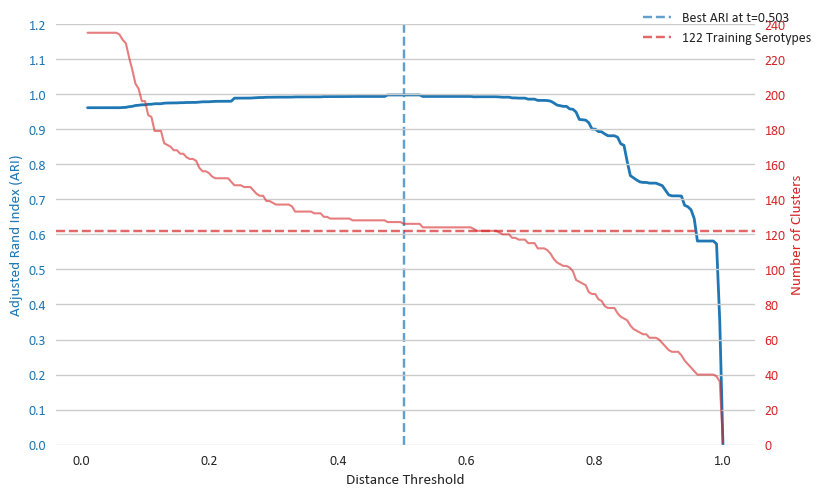

In [20]:
import matplotlib.font_manager
import matplotlib.font_manager as fm
import seaborn as sns
fm.fontManager.__init__()
fonts = [f.name for f in matplotlib.font_manager.fontManager.ttflist]
print(fonts)
plt.style.use('seaborn-v0_8')
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Calibri']
sns.set_style("white")

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Calibri"],
    "font.size": 11,
})
fig, ax1 = plt.subplots(figsize=(8.27, 5))

color = "tab:blue"
ax1.set_xlabel("Distance Threshold")
ax1.set_ylabel("Adjusted Rand Index (ARI)", color=color)
ax1 = sns.lineplot(x=results_df["threshold"], y=results_df["nmi"], color=color, lw=2)
ax1.axvline(best_threshold, color=color, linestyle="--", alpha=0.7,
            label=f"Best ARI at t={best_threshold:.3f}")
ax1.tick_params(axis="y", labelcolor=color)
ax1.set_ylim(0, 1.1)
ax1.set_yticks(np.arange(0, 1.25, 0.1))
#ax1.legend()

ax2 = ax1.twinx()
ax2.set_ylim(0.0, 240.0)
ax2.set_yticks(np.arange(0, 241, 20))
color = "tab:red"
ax2.set_ylabel("Number of Clusters", color=color)
ax2 = sns.lineplot(x=results_df["threshold"], y=results_df["n_clusters"], color=color, lw=1.5, alpha=0.6)
ax2.tick_params(axis="y", labelcolor=color)
ax2.axhline(y=122, color=color, linestyle="--", alpha=0.7, label="122 Training Serotypes")
fig.legend()
#plt.title("Threshold Optimisation: Maximising Serotype Concordance")
plt.grid(True)

fig.tight_layout()

plt.savefig("threshold_optimisation.pdf", dpi=300, format="pdf")
plt.show()

In [13]:
from collections import Counter
from tqdm import tqdm
# Only proceed if we have enough samples per serotype for stratification
min_class_size = 3
class_counts = Counter(train_labels.values)
valid_classes = {c for c, n in class_counts.items() if n >= min_class_size}
print("1")
if len(valid_classes) >= 2:
    cv_mask = train_labels.isin(valid_classes)
    cv_matrix = train_matrix[cv_mask]
    cv_labels = train_labels[cv_mask]
    print("2")
    n_splits = min(5, min(class_counts[c] for c in valid_classes))
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

    # Hierarchical clustering cannot predict out-of-fold, so we cut the full
    # tree and score only the held-out indices. The full linkage tree is
    # identical for every fold and threshold, so compute it ONCE upfront
    # instead of recomputing it at every threshold of every fold (the old bottleneck).
    full_dist = pdist(cv_matrix.values, metric="jaccard")
    full_z = linkage(full_dist, method="average")

    cv_results = []
    for fold, (train_idx, test_idx) in tqdm(enumerate(skf.split(cv_matrix, cv_labels), 1)):
        # Build training-fold linkage only to bound the threshold grid
        fold_dist = pdist(cv_matrix.iloc[train_idx].values, metric="jaccard")
        fold_z = linkage(fold_dist, method="average")
        for t in np.linspace(0.01, np.max(fold_z[:, 2]), 100):
            clusters = fcluster(full_z, t=t, criterion="distance")

            ari = adjusted_rand_score(cv_labels.values[test_idx], clusters[test_idx])
            cv_results.append({"fold": fold, "threshold": t, "ari": ari})

    cv_df = pd.DataFrame(cv_results)
    mean_ari = cv_df.groupby("threshold")["ari"].mean()
    best_cv_threshold = mean_ari.idxmax()
    print(f"Cross-validated optimal threshold: {best_cv_threshold:.4f}  (mean ARI = {mean_ari.max():.4f})")
else:
    print("Warning: Too few samples per serotype for stratified cross-validation. Using single-split optimisation.")
    best_cv_threshold = best_threshold

1
2


5it [00:27,  5.45s/it]

Cross-validated optimal threshold: 0.5000  (mean ARI = 0.9979)


In [14]:
# Compute linkage on the FULL dataset
from scipy.spatial.distance import pdist, squareform
full_dist = pdist(pa.values, metric="jaccard")

square_dist_matrix = pd.DataFrame(squareform(full_dist), index=pa.index)


In [15]:
# Compute linkage on the FULL dataset

full_z = linkage(full_dist, method="average")

# Cut the tree at the validated threshold
final_threshold = best_cv_threshold if "best_cv_threshold" in dir() else best_threshold
final_clusters = fcluster(full_z, t=final_threshold, criterion="distance")

# Append cluster assignments to the matrix
pa["cluster"] = final_clusters
pa.to_csv("oag_locus_clusters_optimised.tsv", sep="\t")

print(f"Final clustering: {len(set(final_clusters))} clusters from {len(pa)} loci")

# Summary: how many serotypes map to each cluster?
if "serotype" in pa.columns:
    pa = pa.drop(columns="serotype", errors="ignore")
pa_labelled = pa.loc[pa.index.intersection(seqs_otypes_final_df.index)].copy()
pa_labelled["serotype"] = seqs_otypes_final_df["serotype"]
pa_labelled.to_csv("oag_locus_serotype.csv")
cluster_purity = (
    pa_labelled.groupby("cluster")["serotype"]
    .apply(lambda s: s.value_counts().iloc[0] / len(s) if len(s) > 0 else 0)
    .rename("majority_fraction")
)
print("\nCluster purity (fraction of majority serotype among labelled members):")
print(cluster_purity.sort_values(ascending=False).head(10))

Final clustering: 251 clusters from 4310 loci

Cluster purity (fraction of majority serotype among labelled members):
cluster
1      1.0
171    1.0
162    1.0
163    1.0
164    1.0
165    1.0
166    1.0
167    1.0
168    1.0
170    1.0
Name: majority_fraction, dtype: float64


In [16]:
# Identify ecoh mismatches and their cluster assignments
# Cell 6 (eda7d7507c53f0b3) flagged loci where ecoh returned two different O-types.
# This cell collects those mismatches and maps them to the clusters assigned above.

mismatches = []
for seq, otypes in seqs_otypes.items():
    if len(otypes) == 2 and otypes[0] != otypes[1]:
        mismatches.append({
            "locus": seq,
            "ecoh_call_1": otypes[0],
            "ecoh_call_2": otypes[1],
        })

mismatch_df = pd.DataFrame(mismatches)

# Look up cluster assignment for each mismatched locus
mismatch_df["cluster"] = mismatch_df["locus"].map(pa["cluster"])

# Drop loci that were filtered out of the clustering (NaN cluster)
mismatch_df = mismatch_df.dropna(subset=["cluster"]).copy()
mismatch_df["cluster"] = mismatch_df["cluster"].astype(int)

print(f"Total ecoh mismatches: {len(mismatch_df)}")
print("\nMismatched loci and their clusters:")
print(mismatch_df.sort_values("cluster").to_string(index=False))

# Summarize: how many mismatches per cluster?
cluster_mismatch_counts = mismatch_df["cluster"].value_counts().sort_index()
print(f"\nClusters containing mismatches: {len(cluster_mismatch_counts)}")
print(cluster_mismatch_counts.head(20))

# For clusters with mismatches, show the serotype composition of labelled members
print("\n--- Cluster composition for clusters with mismatches ---")
for cid in sorted(mismatch_df["cluster"].unique()):
    members = pa_labelled[pa_labelled["cluster"] == cid]
    sero_counts = members["serotype"].value_counts()
    mismatch_loci = mismatch_df[mismatch_df["cluster"] == cid]["locus"].tolist()
    print(f"\nCluster {cid} (n={len(members)}, mismatches={len(mismatch_loci)}):")
    print(f"  Serotypes: {dict(sero_counts)}")
    print(f"  Mismatch loci: {mismatch_loci}")

mismatch_df.to_csv("ecoh_mismatches_by_cluster.tsv", sep="\t", index=False)
print("\nSaved: ecoh_mismatches_by_cluster.tsv")

Total ecoh mismatches: 297

Mismatched loci and their clusters:
               locus     ecoh_call_1        ecoh_call_2  cluster
       NZ_CP115186.1              O8           O153var2        1
       NZ_CP053787.1              O8           O153var2        1
       NZ_CP195143.1              O8           O153var2        1
       NZ_CP159644.1              O8           O153var2        1
       NZ_CP074366.1              O8           O153var2        1
       NZ_CP050047.1              O8           O153var2        1
NZ_ABACVG020000001.1              O8           O153var2        1
       NZ_CP159641.1              O8           O153var2        1
       NZ_CP027472.1        O118-Gp3           O151-Gp3       33
       NZ_CP029180.1        O118-Gp3           O151-Gp3       33
       NZ_CP027582.1        O118-Gp3           O151-Gp3       33
       NZ_CP159875.1        O118-Gp3           O151-Gp3       33
       NZ_CP062211.1        O118-Gp3           O151-Gp3       33
       NZ_CP112988.1      

In [17]:
# Identify loci with no predicted serotype by ecoh and their cluster assignments
# A "no call" locus is one that appears in the clustering matrix but is NOT in
# seqs_otypes_final (i.e. ecoh did not return exactly 2 matching calls).

all_loci = set(pa.index)
confident_loci = set(seqs_otypes_final.index)

# Loci without a confident serotype call
no_call_loci = sorted(all_loci - confident_loci)

# Categorise why each locus has no call
no_call_records = []
for seq in no_call_loci:
    otypes = seqs_otypes.get(seq, [])
    if len(otypes) == 0:
        reason = "no_ecoh_hits"
    elif len(otypes) == 1:
        reason = "single_hit"
    elif len(otypes) == 2 and otypes[0] != otypes[1]:
        reason = "mismatch"  # already covered in previous cell, kept for completeness
    elif len(otypes) > 2:
        reason = f"multiple_hits_{len(otypes)}"
    else:
        reason = "unknown"
    no_call_records.append({
        "locus": seq,
        "reason": reason,
        "ecoh_calls": ",".join(otypes) if otypes else "",
    })

no_call_df = pd.DataFrame(no_call_records)

# Look up cluster assignment
no_call_df["cluster"] = no_call_df["locus"].map(pa["cluster"])
no_call_df = no_call_df.dropna(subset=["cluster"]).copy()
no_call_df["cluster"] = no_call_df["cluster"].astype(int)

print(f"Total loci in clustering: {len(all_loci)}")
print(f"Loci with confident ecoh call: {len(confident_loci)}")
print(f"Loci with no predicted serotype: {len(no_call_df)}")
print(f"\nBreakdown by reason:")
print(no_call_df["reason"].value_counts())

print(f"\nNo-call loci and their clusters (first 20):")
print(no_call_df.sort_values("cluster").head(20).to_string(index=False))

# Summarise: how many no-call loci per cluster?
cluster_nocall_counts = no_call_df["cluster"].value_counts().sort_index()
print(f"\nClusters containing no-call loci: {len(cluster_nocall_counts)}")
print(cluster_nocall_counts.head(20))

# For clusters with no-call loci, show the serotype composition of labelled members
print("\n--- Cluster composition for clusters with no-call loci ---")
for cid in sorted(no_call_df["cluster"].unique())[:20]:
    members = pa_labelled[pa_labelled["cluster"] == cid]
    sero_counts = members["serotype"].value_counts() if len(members) > 0 else pd.Series(dtype=int)
    nocall_loci = no_call_df[no_call_df["cluster"] == cid]["locus"].tolist()
    print(f"\nCluster {cid} (labelled={len(members)}, no-calls={len(nocall_loci)}):")
    if len(sero_counts) > 0:
        print(f"  Serotypes: {dict(sero_counts)}")
    else:
        print(f"  Serotypes: (none labelled)")
    print(f"  No-call loci: {nocall_loci}")

no_call_df.to_csv("ecoh_no_call_by_cluster.tsv", sep="\t", index=False)
print("\nSaved: ecoh_no_call_by_cluster.tsv")


Total loci in clustering: 4310
Loci with confident ecoh call: 3704
Loci with no predicted serotype: 606

Breakdown by reason:
reason
mismatch           297
no_ecoh_hits       256
single_hit          49
multiple_hits_3      4
Name: count, dtype: int64

No-call loci and their clusters (first 20):
               locus       reason  ecoh_calls  cluster
       NZ_CP074366.1     mismatch O8,O153var2        1
       NZ_CP050047.1     mismatch O8,O153var2        1
NZ_ABACVG020000001.1     mismatch O8,O153var2        1
       NZ_CP053787.1     mismatch O8,O153var2        1
       NZ_CP159644.1     mismatch O8,O153var2        1
       NZ_CP159641.1     mismatch O8,O153var2        1
       NZ_CP115186.1     mismatch O8,O153var2        1
       NZ_CP195143.1     mismatch O8,O153var2        1
       NZ_CP070902.1 no_ecoh_hits                    4
       NZ_CP101666.1 no_ecoh_hits                    6
       NZ_CP025048.1 no_ecoh_hits                    6
       NZ_CP063487.1 no_ecoh_hits           

In [18]:
# Calculate serotype purity: how many clusters map to each serotype
# For each serotype, count the clusters it appears in and measure cluster purity.

# Build a locus-level table with serotype and cluster
sero_cluster = pa_labelled[["serotype", "cluster"]].copy()

# --- 1. Clusters per serotype ---
clusters_per_serotype = (
    sero_cluster.groupby("serotype")["cluster"]
    .nunique()
    .sort_values(ascending=False)
    .rename("n_clusters")
)

# --- 2. Purity of each (serotype, cluster) combination ---
# For every cluster that contains a given serotype, what fraction of that cluster is that serotype?
cluster_sizes = pa_labelled.groupby("cluster").size().rename("cluster_size")

sero_cluster_counts = (
    sero_cluster.groupby(["serotype", "cluster"])
    .size()
    .rename("serotype_in_cluster")
    .reset_index()
)

sero_cluster_counts = sero_cluster_counts.merge(cluster_sizes, left_on="cluster", right_index=True)
sero_cluster_counts["purity"] = sero_cluster_counts["serotype_in_cluster"] / sero_cluster_counts["cluster_size"]

# --- 3. Best purity per serotype ---
best_purity_per_serotype = (
    sero_cluster_counts.groupby("serotype")["purity"]
    .max()
    .rename("best_purity")
)

# --- 4. Mean purity per serotype (weighted by cluster size) ---
weighted_mean_purity = (
    sero_cluster_counts.groupby("serotype")
    .apply(lambda df: (df["purity"] * df["cluster_size"]).sum() / df["cluster_size"].sum())
    .rename("weighted_mean_purity")
)

# Combine into summary table
serotype_summary = pd.concat([
    clusters_per_serotype,
    best_purity_per_serotype,
    weighted_mean_purity,
], axis=1)

serotype_summary["loci_count"] = sero_cluster["serotype"].value_counts()
serotype_summary = serotype_summary[["loci_count", "n_clusters", "best_purity", "weighted_mean_purity"]]
serotype_summary = serotype_summary.sort_values("n_clusters", ascending=False)

print("Serotype purity summary (top 20):")
print(serotype_summary.head(20).to_string())

# --- 5. Identify "impure" serotypes (spread across >1 cluster with low purity) ---
impure = serotype_summary[
    (serotype_summary["n_clusters"] > 1) &
    (serotype_summary["best_purity"] < 0.9)
].sort_values("weighted_mean_purity")

print(f"\n\nImpure serotypes (spread across >1 cluster, best purity < 0.9): {len(impure)}")
print(impure.head(20).to_string())

# --- 6. Identify "pure" serotypes (single cluster, purity = 1.0) ---
pure = serotype_summary[
    (serotype_summary["n_clusters"] == 1) &
    (serotype_summary["best_purity"] == 1.0)
]
print(f"\n\nPerfectly pure serotypes (1 cluster, purity = 1.0): {len(pure)}")
print(pure.head(20).to_string())

# --- 7. Detailed breakdown for serotypes that appear in multiple clusters ---
print("\n\n--- Detailed breakdown for serotypes in multiple clusters ---")
multi_cluster_sero = serotype_summary[serotype_summary["n_clusters"] > 1].index

for sero in multi_cluster_sero[:10]:
    sub = sero_cluster_counts[sero_cluster_counts["serotype"] == sero].sort_values("purity", ascending=False)
    print(f"\n{sero} (loci={serotype_summary.loc[sero, 'loci_count']}):")
    for _, row in sub.iterrows():
        print(f"  Cluster {int(row['cluster'])}: {row['serotype_in_cluster']}/{row['cluster_size']} loci "
              f"(purity={row['purity']:.2f})")

serotype_summary.to_csv("serotype_purity_summary.tsv", sep="\t")
sero_cluster_counts.to_csv("serotype_cluster_purity.tsv", sep="\t", index=False)
print("\nSaved: serotype_purity_summary.tsv, serotype_cluster_purity.tsv")


Serotype purity summary (top 20):
          loci_count  n_clusters  best_purity  weighted_mean_purity
serotype                                                           
O112              19           2          1.0                   1.0
O8                61           2          1.0                   1.0
O6               128           2          1.0                   1.0
O45               61           2          1.0                   1.0
O113              24           2          1.0                   1.0
O110               1           1          1.0                   1.0
O102             102           1          1.0                   1.0
O103              28           1          1.0                   1.0
O104              37           1          1.0                   1.0
O105              10           1          1.0                   1.0
O108               6           1          1.0                   1.0
O108var1          11           1          1.0                   1.0
O109          